# Replication: Ramzan et al. 2024 - Multimodal anemia detection (EHR + images), RCBAM-MobileNetV2
Paper pipeline (Discover Artificial Intelligence 4:100): ROI extraction -> EHR feature selection (odds ratio + chi-square) -> MobileNetV2 / CBAM-MobileNetV2 / **RCBAM-MobileNetV2** -> **Grad-CAM** -> R/G/B pixel-percentage features -> fusion with EHR -> LR / DT / RF / SVM / NB / KNN (+SMOTE, GridSearchCV) -> Accuracy, AUC, Precision, Recall, F1, confusion matrix, ROC, PR, calibration, feature importance, ablation.

The paper used conjunctiva images; here the three image sources (palmas, unas, yemas) each play the role of the image modality, one after another.

Run cells top to bottom. All heavy steps are checkpointed in `/kaggle/working/anemia_ramzan_ckpt`; after an interruption re-run all cells and finished work is skipped (CNN training resumes from the last epoch).

## Three-class update
This version classifies **Normal (0), Leve (1), and Moderada (2)**. It does not collapse the labels into Anemic/Non-anemic. The Hb-derived fallback uses configurable thresholds in Cell 1; confirm those thresholds against the dataset/clinical protocol. If the dataset already has severity labels, those labels are preferred.


## Debugging note (fixed version)

- Grid search uses `f1_macro`, which is appropriate for this 3-class classification task. The previous `f1` scorer used binary averaging and produced `ValueError: Target is multiclass but average='binary'`.
- The number of stratified CV folds is capped by the smallest class count; if a class has fewer than two training samples, grid search is skipped for that classifier rather than failing.
- Notebook outputs were cleared so that old warning logs are not mistaken for results from the corrected code.

Run the notebook from top to bottom in the Kaggle environment. Dataset paths still need to exist under `/kaggle/input/...`; this environment cannot execute the Kaggle-specific training pipeline against your mounted Kaggle datasets.


In [30]:
# CELL 1 - setup
import os, re, json, random, warnings, time, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings("ignore")
try:
    import imblearn
except ImportError:
    os.system("pip install -q imbalanced-learn"); import imblearn

MANUAL_PATHS = {
    "csv": "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",
    "yemas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",
    "unas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",
}
SITES = ["palmas", "unas", "yemas"]       # image modality, one after another (paper: conjunctiva)

CFG = dict(
    SEED=42,
    IMG_SIZE=224,                 # paper: 224 x 224 input
    TEST_FRAC=0.30,               # paper confusion matrix: 214 test of 710 images = 30%
    VAL_FRAC_OF_TRAIN=0.10,       # validation carved out of train for CNN training only
    SPLIT_BY_PATIENT=False,       # False = random split of images (paper). True = no patient shared between train/test
    CNN_EPOCHS=20, CNN_BATCH=32, CNN_LR=1e-4, CNN_DROPOUT=0.3,   # not given in paper
    GRADCAM_THR=0.5,              # heatmap threshold that defines the "highlighted region" (not given in paper)
    BALANCE="smote",              # paper: SMOTE / ADASYN for class imbalance. "smote" | "adasyn" | "none"
    GS_CV=5, GS_SCORING="f1_macro",  # multiclass-safe GridSearchCV objective
    SELECT_K=50,                  # paper Table 3: SelectKBest
    HB_NORMAL_THRESHOLD=11.0,     # Hb >= this -> Normal (adjust to your dataset's clinical protocol)
    HB_MODERADA_THRESHOLD=8.0,  # Hb below this -> Moderada; between thresholds -> Leve (adjust as needed)
    MAX_IMAGES_PER_SITE=None,     # e.g. 3000 to limit time; None = use all images
    FORCE_RERUN=False,
)
WORK = Path("/kaggle/working/anemia_ramzan_3class_ckpt")
for d in ["roi", "features", "results", "cnn", "models", "plots"]:
    (WORK / d).mkdir(parents=True, exist_ok=True)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
print("checkpoint dir:", WORK)

checkpoint dir: /kaggle/working/anemia_ramzan_3class_ckpt


In [17]:
# CELL 2 - explore the data (look at this output)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)

for k in ["csv", "metadata"]:
    try:
        df_ = pd.read_csv(MANUAL_PATHS[k])
        print(f"\n===== {k}: shape={df_.shape}"); print(list(df_.columns)); display(df_.head())
    except Exception as e:
        print(f"\n===== {k}: could not read ({e})")
for s in SITES:
    imgs = list_images(MANUAL_PATHS[s]); root = Path(MANUAL_PATHS[s])
    print(f"\n===== {s}: {len(imgs)} images")
    for p in imgs[:5]: print("  ", p.relative_to(root))
    subdirs = sorted({str(p.parent.relative_to(root)) for p in imgs})
    print("   subfolders:", subdirs[:10], "..." if len(subdirs) > 10 else "")


===== csv: shape=(999, 7)
['ID', 'Class', 'Anemia Predict', 'Split', 'YEMAS Path', 'PALMAS Path', 'UNAS Path']


,ID,Class,Anemia Predict,Split,YEMAS Path,PALMAS Path,UNAS Path
0,ID001,Normal,0,train,dataset/yemas/Normal/20230706_211043.mp4,dataset/palmas/Normal/20230706_211218.mp4,dataset/unas/Normal/20230706_211246.jpg
1,ID002,Normal,0,train,NaN,NaN,NaN
2,ID003,Normal,0,train,dataset/yemas/Normal/20230706_205929.mp4,dataset/palmas/Normal/20230706_210050.mp4,dataset/unas/Normal/20230706_210140.jpg
3,ID004,Leve,1,train,dataset/yemas/Leve/20230706_205753.mp4,dataset/palmas/Leve/20230706_205901.mp4,dataset/unas/Leve/20230706_205941.jpg
4,ID005,Moderada,1,validation,dataset/yemas/Moderada/20230706_205551.mp4,dataset/palmas/Moderada/20230706_205659.mp4,dataset/unas/Moderada/20230706_205732.jpg



===== metadata: shape=(909, 22)
['ID', 'Sexo', 'Edad', 'Fatiga', 'Debilidad', 'Latidos irregulares', 'Dificultad para respirar', 'Mareos o aturdimiento', 'Dolor en el pecho', 'Manos y pies fríos', 'Dolores de cabeza', 'Normal', 'Leve', 'Moderado', 'Frecuencia Cardiaca', 'Hemoglobina', 'Oxígeno', 'Peso', 'Talla', 'YEMAS', 'PALMAS', 'UNAS']


,ID,Sexo,Edad,Fatiga,Debilidad,Latidos irregulares,Dificultad para respirar,Mareos o aturdimiento,Dolor en el pecho,Manos y pies fríos,...,Leve,Moderado,Frecuencia Cardiaca,Hemoglobina,Oxígeno,Peso,Talla,YEMAS,PALMAS,UNAS
0,ID001,M,25,0,0,1,0,0,0,0,...,0,0,70.0,13.6,98,89.0,183.0,20230706_211043.mp4,20230706_211218.mp4,20230706_211246.jpg
1,ID002,M,25,1,1,0,0,0,0,0,...,0,0,77.0,13.7,98,76.0,165.0,NaN,NaN,NaN
2,ID003,M,23,0,0,0,0,1,0,0,...,0,0,66.0,14.3,98,64.8,159.0,20230706_205929.mp4,20230706_210050.mp4,20230706_210140.jpg
3,ID004,F,23,1,1,0,1,1,1,1,...,1,0,85.0,11.5,99,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg
4,ID005,F,24,0,0,0,0,0,0,0,...,0,1,75.0,10.8,98,64.1,152.0,20230706_205551.mp4,20230706_205659.mp4,20230706_205732.jpg



===== palmas: 13328 images
   Leve/ID004/frame_000.jpg
   Leve/ID004/frame_001.jpg
   Leve/ID004/frame_002.jpg
   Leve/ID004/frame_003.jpg
   Leve/ID004/frame_004.jpg
   subfolders: ['Leve/ID004', 'Leve/ID015', 'Leve/ID018', 'Leve/ID019', 'Leve/ID020', 'Leve/ID021', 'Leve/ID022', 'Leve/ID024', 'Leve/ID026', 'Leve/ID028'] ...

===== unas: 826 images
   Leve/ID004.jpg
   Leve/ID015.jpg
   Leve/ID018.jpg
   Leve/ID019.jpg
   Leve/ID020.jpg
   subfolders: ['Leve', 'Moderada', 'Normal'] 

===== yemas: 26816 images
   Leve/ID004/frame_000.jpg
   Leve/ID004/frame_001.jpg
   Leve/ID004/frame_002.jpg
   Leve/ID004/frame_003.jpg
   Leve/ID004/frame_004.jpg
   subfolders: ['Leve/ID004', 'Leve/ID015', 'Leve/ID018', 'Leve/ID019', 'Leve/ID020', 'Leve/ID021', 'Leve/ID022', 'Leve/ID024', 'Leve/ID026', 'Leve/ID028'] ...


In [18]:
# CELL 3 - image index, THREE labels (Normal / Leve / Moderada), and EHR columns
# If auto-detection picks wrong columns, set these:
CSV_ID_COL    = None     # id column (patient / image name) in the csv files
CSV_LABEL_COL = None     # label column (Normal/Leve/Moderada, 0/1/2, or Hb value)
PATIENT_ID_FN = None     # optional: lambda stem -> patient id
EHR_COLS      = None     # optional: list of csv column names to use as EHR candidates

CLASS_NAMES = ["Normal", "Leve", "Moderada"]
CLASS_TO_ID = {"normal": 0, "leve": 1, "moderada": 2}

def label_from_text(value):
    """Map dataset labels to 0=Normal, 1=Leve, 2=Moderada; unsupported labels are excluded."""
    t = str(value).strip().lower()
    # Match severity before generic anemia words.
    if re.search(r"moderad|moderate|moderately", t):
        return 2
    if re.search(r"\bleve\b|mild|light anemia", t):
        return 1
    if re.search(r"normal|non[\s_\-]?anem|no[\s_\-]?anem|healthy|sano|control|negativ", t):
        return 0
    return None

def default_pid(stem):
    return re.sub(r"[_\-\s]*(frame|fr)[_\-\s]*\d+$", "", stem, flags=re.I)
def norm(x):
    s = str(x).strip().lower()
    return Path(s).stem if re.search(r"\.(jpg|jpeg|png|bmp|tif|tiff)$", s) else s
def pick_col(df, keys):
    for c in df.columns:
        if any(k in c.lower() for k in keys): return c
    return None

rows = []
for site in SITES:
    root = Path(MANUAL_PATHS[site])
    for p in list_images(root):
        rel = str(p.relative_to(root))
        pid = PATIENT_ID_FN(p.stem) if PATIENT_ID_FN else default_pid(p.stem)
        rows.append(dict(site=site, path=str(p), rel=rel, stem=p.stem, parent=p.parent.name,
                         patient=str(pid), label=label_from_text(rel)))
idx = pd.DataFrame(rows)
if CFG["MAX_IMAGES_PER_SITE"]:
    idx = idx.groupby("site", group_keys=False).apply(
        lambda d: d.sample(min(len(d), CFG["MAX_IMAGES_PER_SITE"]), random_state=CFG["SEED"])).reset_index(drop=True)
print(f"labels from folder/file names: {idx.label.notna().mean():.1%}")

# ---- match CSV rows to images
sources, matched = {}, {}
for name in ["csv", "metadata"]:
    try: src = pd.read_csv(MANUAL_PATHS[name])
    except Exception as e: print(name, "unreadable:", e); continue
    id_col = CSV_ID_COL if CSV_ID_COL in src.columns else pick_col(src, ["id", "name", "file", "image", "patient", "sample"])
    if id_col is None: print(f"[{name}] no id column found"); continue
    lookup = {}
    for i_, k_ in enumerate(src[id_col].map(norm)): lookup.setdefault(k_, i_)
    rowpos = []
    for r in idx.itertuples():
        pos = -1
        for key in (norm(r.patient), norm(r.stem), norm(r.parent)):
            if key in lookup: pos = lookup[key]; break
        rowpos.append(pos)
    cov = float(np.mean(np.array(rowpos) >= 0))
    print(f"[{name}] id_col={id_col!r}: {cov:.1%} of images matched to a row")
    if cov >= 0.5:
        sources[name] = (src, id_col); matched[name] = np.array(rowpos)

def to_label(v, hb_mode):
    if pd.isna(v): return None
    if hb_mode:
        try:
            hb = float(v)
            if hb >= CFG["HB_NORMAL_THRESHOLD"]: return 0
            if hb >= CFG["HB_MODERADA_THRESHOLD"]: return 1
            return 2
        except: return None
    # Numeric category codes 0/1/2 are kept as three classes.
    if isinstance(v, (int, float, np.integer, np.floating)):
        iv = int(v)
        return iv if float(v) == iv and iv in (0, 1, 2) else None
    return label_from_text(v)

label_cols = {}
if idx.label.notna().mean() < 0.9:
    best = (0, None)
    for name, (src, id_col) in sources.items():
        lab_col = CSV_LABEL_COL if CSV_LABEL_COL in src.columns else pick_col(src, ["severity", "anem", "label", "class", "result", "hb", "hemo"])
        if lab_col is None: continue
        hb_mode = pd.api.types.is_numeric_dtype(src[lab_col]) and (
            any(k in lab_col.lower() for k in ["hb", "hemo"]) or src[lab_col].dropna().max() > 2)
        vals = [to_label(src[lab_col].iloc[p], hb_mode) if p >= 0 else None for p in matched[name]]
        cov = pd.Series(vals).notna().mean()
        print(f"[{name}] label_col={lab_col!r} hb_mode={hb_mode} -> labelled {cov:.1%}")
        if cov > best[0]: best = (cov, vals, name, lab_col)
    if best[1] is not None and best[0] > idx.label.notna().mean():
        idx["label"] = best[1]; label_cols[best[2]] = best[3]; print("labels taken from", best[2], best[3])

n0 = len(idx)
keep = idx.label.isin([0, 1, 2]).values
idx = idx[keep].copy(); idx["label"] = idx.label.astype(int)
for name in matched: matched[name] = matched[name][keep]
idx = idx.reset_index(drop=True)
print(f"labelled images in selected classes: {len(idx)}/{n0}")
print("Class counts:", idx.label.map(dict(enumerate(CLASS_NAMES))).value_counts().to_dict())
if len(idx) < 0.5 * n0:
    raise RuntimeError("Less than 50% of images mapped to Normal/Leve/Moderada. Check folder names/CSV labels, "
                       "and set CSV_ID_COL / CSV_LABEL_COL if needed.")

# ---- EHR candidate columns; exclude label/severity/Hb to avoid leakage
EXCL = ["hb", "hemo", "sever", "result", "label", "class", "anem", "file", "image", "name", "path",
        "patient", "sample", "frame", "date", "time", "unnamed", "id"]
PROTECT = ["age", "gender", "sex"]
def is_candidate(c, id_col, lab_col):
    cl = str(c).lower()
    if c == id_col or c == lab_col: return False
    if any(p in cl for p in PROTECT): return True
    return not any(k in cl for k in EXCL)
ehr_raw = {}
for name, (src, id_col) in sources.items():
    cols = [c for c in (EHR_COLS or src.columns) if c in src.columns and (EHR_COLS or is_candidate(c, id_col, label_cols.get(name)))]
    for c in cols:
        if c in ehr_raw: continue
        ehr_raw[c] = [src[c].iloc[p] if p >= 0 else np.nan for p in matched[name]]
ehr_raw = pd.DataFrame(ehr_raw)
print("EHR candidate columns:", list(ehr_raw.columns))
print(idx.groupby(["site", "label"]).size().unstack(fill_value=0).rename(columns=dict(enumerate(CLASS_NAMES))))
print("unique patients:", idx.patient.nunique())
display(pd.concat([idx[["site", "patient", "label"]], ehr_raw], axis=1).head())


labels from folder/file names: 100.0%
[csv] id_col='ID': 99.5% of images matched to a row
[metadata] id_col='ID': 99.5% of images matched to a row
labelled images in selected classes: 40970/40970
Class counts: {'Normal': 27367, 'Leve': 9946, 'Moderada': 3657}
EHR candidate columns: ['Split', 'Sexo', 'Edad', 'Fatiga', 'Dificultad para respirar', 'Mareos o aturdimiento', 'Dolor en el pecho', 'Manos y pies fríos', 'Dolores de cabeza', 'Normal', 'Leve', 'Moderado', 'Frecuencia Cardiaca', 'Oxígeno', 'Peso', 'Talla', 'YEMAS', 'PALMAS', 'UNAS']
label   Normal  Leve  Moderada
site                          
palmas    8896  3248      1184
unas       551   202        73
yemas    17920  6496      2400
unique patients: 827


,site,patient,label,Split,Sexo,Edad,Fatiga,Dificultad para respirar,Mareos o aturdimiento,Dolor en el pecho,...,Normal,Leve,Moderado,Frecuencia Cardiaca,Oxígeno,Peso,Talla,YEMAS,PALMAS,UNAS
0,palmas,,1,train,F,23,1.0,1.0,1.0,1.0,...,0.0,1.0,0.0,85.0,99.0,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg
1,palmas,,1,train,F,23,1.0,1.0,1.0,1.0,...,0.0,1.0,0.0,85.0,99.0,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg
2,palmas,,1,train,F,23,1.0,1.0,1.0,1.0,...,0.0,1.0,0.0,85.0,99.0,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg
3,palmas,,1,train,F,23,1.0,1.0,1.0,1.0,...,0.0,1.0,0.0,85.0,99.0,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg
4,palmas,,1,train,F,23,1.0,1.0,1.0,1.0,...,0.0,1.0,0.0,85.0,99.0,70.2,159.0,20230706_205753.mp4,20230706_205901.mp4,20230706_205941.jpg


In [19]:
# CELL 4 - ROI extraction: entropy-grayscale + triangle thresholding (as in the dataset used by the paper), checkpointed
import cv2
from skimage.filters.rank import entropy as sk_entropy
from skimage.morphology import disk
from tqdm.auto import tqdm
S = CFG["IMG_SIZE"]
idx["roi_path"] = [str(WORK / "roi" / f"{r.site}_{i:06d}.png") for i, r in enumerate(idx.itertuples())]

def roi_extract(bgr):
    bgr = cv2.resize(bgr, (S, S), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    ent = sk_entropy(gray, disk(5)).astype(np.float32)
    ent8 = cv2.normalize(ent, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, bw = cv2.threshold(ent8, 0, 255, cv2.THRESH_TRIANGLE)
    mask = bw > 0
    if mask.mean() < 0.05 or mask.mean() > 0.98:      # degenerate mask -> keep whole image
        mask = np.ones_like(mask, bool)
    out = bgr.copy(); out[~mask] = 0
    return out

todo = [r for r in idx.itertuples() if not os.path.exists(r.roi_path)]
print("ROI images to create:", len(todo), "of", len(idx))
for r in tqdm(todo, desc="ROI"):
    im = cv2.imread(r.path)
    if im is None: continue
    cv2.imwrite(r.roi_path, roi_extract(im))
ok = np.array([os.path.exists(p) for p in idx.roi_path])
ehr_raw = ehr_raw[ok].reset_index(drop=True); idx = idx[ok].reset_index(drop=True)
print("ROI images available:", len(idx))

ROI images to create: 0 of 40970


ROI: 0it [00:00, ?it/s]

ROI images available: 40970


In [20]:
# CELL 5 - EHR preprocessing + feature selection (odds ratio + chi-square), then train/test split
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# ---- encode EHR (paper: Gender 0/1, Age in months) and drop empty / constant columns
E = pd.DataFrame(index=idx.index)
for c in ehr_raw.columns:
    s = ehr_raw[c]
    if not pd.api.types.is_numeric_dtype(s):
        s = s.astype(str).str.strip().str.lower().replace({"nan": np.nan, "none": np.nan, "": np.nan})
        codes, _ = pd.factorize(s, sort=True); s = pd.Series(np.where(codes < 0, np.nan, codes), index=s.index)
    E[c] = pd.to_numeric(s, errors="coerce")
if len(E.columns):
    E = E.loc[:, E.isna().mean() < 0.5]
    E = E.fillna(E.median())
    E = E.loc[:, E.nunique() > 1]

# ---- statistics per column (one row per patient to avoid frame duplication)
first = ~idx.patient.duplicated()
stats = []
for c in E.columns:
    x, y = E.loc[first, c], idx.loc[first, "label"]
    xb = x if x.nunique() <= 6 else pd.qcut(x, 4, duplicates="drop")
    ct = pd.crosstab(xb, y)
    p = chi = np.nan
    if ct.shape[0] >= 2 and ct.shape[1] >= 2: chi, p, *_ = chi2_contingency(ct)
    orr = np.nan
    if x.nunique() == 2:
        t = pd.crosstab(x, y).reindex(columns=[0, 1], fill_value=0).values + 0.5
        orr = (t[1, 1] * t[0, 0]) / (t[1, 0] * t[0, 1])
    stats.append(dict(feature=c, chi2=chi, p_value=p, odds_ratio=orr))
stats = pd.DataFrame(stats)
print("EHR feature statistics (paper: odds ratio + chi-square, p<0.1 treated as notable):")
display(stats)

EHR_SELECT = None   # optional manual override (the paper's medical consultant step), e.g. ["Age", "Gender"]
if EHR_SELECT is None:
    forced = [c for c in E.columns if any(p in str(c).lower() for p in PROTECT)]
    notable = stats.loc[stats.p_value < 0.1, "feature"].tolist() if len(stats) else []
    EHR_SELECT = list(dict.fromkeys(forced + notable))
EHR_SELECT = [c for c in EHR_SELECT if c in E.columns]
HAS_EHR = len(EHR_SELECT) > 0
print("selected EHR features:", EHR_SELECT if HAS_EHR else "NONE (textual / fusion experiments will use image features only)")
EHR_NAMES = [f"ehr_{c}" for c in EHR_SELECT]
for c in EHR_SELECT: idx[f"ehr_{c}"] = E[c].values

# ---- split (paper: 70 / 30), validation part of train used only for CNN training
split_file = WORK / "features" / "split.csv"
if split_file.exists() and not CFG["FORCE_RERUN"] and len(pd.read_csv(split_file)) == len(idx):
    idx["split"] = pd.read_csv(split_file)["split"].values
else:
    idx["split"] = ""
    for site in SITES:
        d = idx[idx.site == site]
        if len(d) == 0: continue
        if CFG["SPLIT_BY_PATIENT"]:
            g = GroupShuffleSplit(1, test_size=CFG["TEST_FRAC"], random_state=CFG["SEED"])
            tr_i, te_i = next(g.split(d, d.label, d.patient))
            tr_idx, te_idx = d.index[tr_i], d.index[te_i]
        else:
            tr_idx, te_idx = train_test_split(d.index, test_size=CFG["TEST_FRAC"], stratify=d.label, random_state=CFG["SEED"])
        tr_idx, va_idx = train_test_split(tr_idx, test_size=CFG["VAL_FRAC_OF_TRAIN"], stratify=idx.loc[tr_idx, "label"], random_state=CFG["SEED"])
        idx.loc[tr_idx, "split"] = "train"; idx.loc[va_idx, "split"] = "val"; idx.loc[te_idx, "split"] = "test"
    idx[["split"]].to_csv(split_file, index=False)
idx.to_csv(WORK / "features" / "index.csv", index=False)
print(idx.groupby(["site", "split", "label"]).size().unstack(fill_value=0))

EHR feature statistics (paper: odds ratio + chi-square, p<0.1 treated as notable):


,feature,chi2,p_value,odds_ratio
0,Split,3.414803,4.909504e-01,NaN
1,Sexo,133.778313,8.920894e-30,0.176867
2,Edad,2.523105,8.658730e-01,NaN
3,Fatiga,9.139867,1.035865e-02,1.210213
4,Dificultad para respirar,9.168719,1.021029e-02,1.921250
5,Mareos o aturdimiento,23.797020,6.800530e-06,1.932372
6,Dolor en el pecho,1.503702,4.714930e-01,1.270805
7,Manos y pies fríos,20.876175,2.929518e-05,1.742268
8,Dolores de cabeza,10.210095,6.066051e-03,1.476773
9,Normal,791.917303,1.089790e-172,0.000039


selected EHR features: ['Sexo', 'Fatiga', 'Dificultad para respirar', 'Mareos o aturdimiento', 'Manos y pies fríos', 'Dolores de cabeza', 'Normal', 'Leve', 'Moderado', 'Frecuencia Cardiaca', 'Peso', 'Talla', 'YEMAS', 'PALMAS', 'UNAS']
label             0     1     2
site   split                   
palmas test    2669   975   355
       train   5604  2046   746
       val      623   227    83
unas   test     165    61    22
       train    347   127    46
       val       39    14     5
yemas  test    5376  1949   720
       train  11289  4092  1512
       val     1255   455   168


In [22]:
# CELL 6 - metrics + classifier machinery (SMOTE / ADASYN + GridSearchCV) + EXPERIMENT A: textual (EHR) dataset
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, matthews_corrcoef)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, ADASYN
import joblib

def compute_metrics(y, prob):
    """Multiclass metrics for class IDs 0=Normal, 1=Leve, 2=Moderada."""
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, float)
    pred = np.argmax(prob, axis=1)
    labels = [0, 1, 2]
    cm = confusion_matrix(y, pred, labels=labels)
    try:
        auc = roc_auc_score(y, prob, labels=labels, multi_class="ovr", average="macro")
    except ValueError:
        auc = float("nan")
    return dict(
        accuracy=accuracy_score(y, pred),
        auc=auc,
        precision=precision_score(y, pred, labels=labels, average="macro", zero_division=0),
        recall=recall_score(y, pred, labels=labels, average="macro", zero_division=0),
        f1=f1_score(y, pred, labels=labels, average="macro", zero_division=0),
        mcc=matthews_corrcoef(y, pred),
        confusion_matrix=cm.tolist(),
        class_names=CLASS_NAMES,
        per_class_precision=precision_score(y, pred, labels=labels, average=None, zero_division=0).tolist(),
        per_class_recall=recall_score(y, pred, labels=labels, average=None, zero_division=0).tolist(),
        per_class_f1=f1_score(y, pred, labels=labels, average=None, zero_division=0).tolist()
    )

CLFS = {
    "LR":  lambda: LogisticRegression(max_iter=2000),
    "DT":  lambda: DecisionTreeClassifier(random_state=CFG["SEED"]),
    "RF":  lambda: RandomForestClassifier(random_state=CFG["SEED"], n_jobs=-1),
    "SVM": lambda: SVC(probability=True, random_state=CFG["SEED"]),
    "NB":  lambda: GaussianNB(),
    "KNN": lambda: KNeighborsClassifier(),
}
GRIDS = {   # include the paper's reported best values (Section 4.4)
    "LR":  {"clf__C": [0.01, 0.1, 1, 10], "clf__solver": ["newton-cg", "lbfgs", "liblinear"]},
    "DT":  {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [1, 3, 5, 10, None]},
    "RF":  {"clf__n_estimators": [50, 100, 200], "clf__max_depth": [1, 3, 5, None]},
    "SVM": {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"]},
    "NB":  {},
    "KNN": {"clf__n_neighbors": [3, 5, 7, 11, 15, 19], "clf__algorithm": ["auto"]},
}
PAPER_PARAMS = {   # paper Section 4.4 ablation (best parameters)
    "SVM": dict(C=0.1, kernel="linear"), "DT": dict(criterion="gini", max_depth=1),
    "LR": dict(C=0.01, solver="newton-cg"), "KNN": dict(n_neighbors=19, algorithm="auto"),
    "RF": dict(max_depth=1, n_estimators=50),
}

def make_pipe(name, y_train, params=None):
    steps = [("scale", StandardScaler())]
    minority = int(np.bincount(np.asarray(y_train).astype(int)).min())
    if CFG["BALANCE"] != "none" and minority > 6:
        k = min(5, minority - 1)
        steps.append(("bal", SMOTE(k_neighbors=k, random_state=CFG["SEED"]) if CFG["BALANCE"] == "smote"
                      else ADASYN(n_neighbors=k, random_state=CFG["SEED"])))
    clf = CLFS[name]()
    if params: clf.set_params(**params)
    steps.append(("clf", clf))
    return ImbPipeline(steps)

def run_clf(site, exp, name, Xtr, ytr, Xte, yte, feat_names, tune=True):
    out = WORK / "results" / f"{site}__{exp}__{name}.json"
    if out.exists() and not CFG["FORCE_RERUN"]:
        return json.load(open(out))
    t0 = time.time()
    if tune:
        pipe = make_pipe(name, ytr)
        grid = GRIDS[name]
        if grid:
            # Multiclass-safe scoring is configured as f1_macro. Also avoid requesting
            # more stratified folds than the smallest class can support.
            min_class_count = int(np.bincount(np.asarray(ytr, dtype=int), minlength=3).min())
            n_splits = min(int(CFG["GS_CV"]), min_class_count)
            if n_splits < 2:
                # GridSearchCV cannot run with fewer than two examples in a class.
                # Fit the default pipeline rather than crashing.
                model = pipe.fit(Xtr, ytr)
                best = {"note": "Grid search skipped: fewer than 2 samples in a class"}
            else:
                gs = GridSearchCV(
                    pipe,
                    grid,
                    cv=StratifiedKFold(n_splits, shuffle=True, random_state=CFG["SEED"]),
                    scoring=CFG["GS_SCORING"],
                    n_jobs=-1,
                    error_score="raise",
                )
                gs.fit(Xtr, ytr)
                model, best = gs.best_estimator_, {k: str(v) for k, v in gs.best_params_.items()}
        else:
            model = pipe.fit(Xtr, ytr); best = {}
    else:
        model = make_pipe(name, ytr, PAPER_PARAMS[name]).fit(Xtr, ytr); best = {k: str(v) for k, v in PAPER_PARAMS[name].items()}
    prob = model.predict_proba(Xte)
    res = dict(site=site, exp=exp, model=name, features=list(feat_names), best_params=best,
               test=compute_metrics(yte, prob), seconds=round(time.time() - t0, 1))
    np.savez(WORK / "results" / f"{site}__{exp}__{name}_probs.npz", y=np.asarray(yte), prob=prob)
    joblib.dump(model, WORK / "models" / f"{site}__{exp}__{name}.joblib")
    json.dump(res, open(out, "w"), indent=1)
    return res

def tr_te(site):
    d = idx[idx.site == site]
    return d[d.split.isin(["train", "val"])], d[d.split == "test"]

# ---------- EXPERIMENT A: textual (EHR) dataset -> LR, DT, RF, SVM, NB, KNN  (paper Table 2, textual rows)
if HAS_EHR:
    for site in SITES:
        tr, te = tr_te(site)
        for name in ["LR", "DT", "RF", "SVM", "NB", "KNN"]:
            r = run_clf(site, "TEXT", name, tr[EHR_NAMES].values, tr.label.values, te[EHR_NAMES].values, te.label.values, EHR_NAMES)
            t = r["test"]; print(f"[TEXT] {site:7s} {name:4s} acc={t['accuracy']:.4f} auc={t['auc']:.4f} prec={t['precision']:.4f} rec={t['recall']:.4f} f1={t['f1']:.4f}")
else:
    print("No EHR features -> experiment A skipped")

[TEXT] palmas  LR   acc=0.9885 auc=0.9958 prec=0.9923 rec=0.9789 f1=0.9854
[TEXT] palmas  DT   acc=0.7539 auc=0.7249 prec=0.5769 rec=0.6582 f1=0.6105
[TEXT] palmas  RF   acc=0.9885 auc=0.9919 prec=0.9923 rec=0.9789 f1=0.9854
[TEXT] palmas  SVM  acc=0.9880 auc=0.9912 prec=0.9886 rec=0.9800 f1=0.9842
[TEXT] palmas  NB   acc=0.9885 auc=0.9912 prec=0.9923 rec=0.9789 f1=0.9854
[TEXT] palmas  KNN  acc=0.9980 auc=0.9991 prec=0.9973 rec=0.9990 f1=0.9981
[TEXT] unas    LR   acc=0.9798 auc=0.9832 prec=0.9864 rec=0.9630 f1=0.9743
[TEXT] unas    DT   acc=0.7500 auc=0.7200 prec=0.5756 rec=0.6515 f1=0.6062
[TEXT] unas    RF   acc=0.9798 auc=0.9893 prec=0.9864 rec=0.9630 f1=0.9743
[TEXT] unas    SVM  acc=0.9798 auc=0.9713 prec=0.9864 rec=0.9630 f1=0.9743
[TEXT] unas    NB   acc=0.9798 auc=0.9832 prec=0.9864 rec=0.9630 f1=0.9743
[TEXT] unas    KNN  acc=0.9718 auc=0.9717 prec=0.9753 rec=0.9590 f1=0.9669
[TEXT] yemas   LR   acc=0.9873 auc=0.9958 prec=0.9916 rec=0.9770 f1=0.9841
[TEXT] yemas   DT   acc=0

In [23]:
# CELL 7 - EXPERIMENT B: image dataset -> MobileNetV2, CBAM-MobileNetV2, RCBAM-MobileNetV2 (paper Table 2, image rows)
import tensorflow as tf
from tensorflow.keras import layers, callbacks, Model
print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
tf.keras.utils.set_random_seed(CFG["SEED"])
S = CFG["IMG_SIZE"]; AUTOTUNE = tf.data.AUTOTUNE
VARIANTS = ["MobileNetV2", "CBAM_MobileNetV2", "RCBAM_MobileNetV2"]

# ---- attention blocks (paper Section 3.4)
def channel_att(x, ratio=8):
    C = int(x.shape[-1]); d0 = layers.Dense(max(C // ratio, 1), activation="relu"); d1 = layers.Dense(C)
    a = layers.Add()([d1(d0(layers.GlobalAveragePooling2D()(x))), d1(d0(layers.GlobalMaxPooling2D()(x)))])   # shared MLP W1(W0(.))
    a = layers.Reshape((1, 1, C))(layers.Activation("sigmoid")(a))
    return layers.Multiply()([x, a])

def spatial_att(x):
    avg = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True))(x)
    mx = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True))(x)
    m = layers.Conv2D(1, 7, padding="same", activation="sigmoid")(layers.Concatenate()([avg, mx]))        # f^{7x7}
    return layers.Multiply()([x, m])

def cbam(x):                 # standard CBAM: channel -> spatial
    return spatial_att(channel_att(x))

def rcbam(x, scales=(1.0, 0.5, 0.25)):
    # Reverse CBAM: spatial -> channel, multi-scale (1.0 / 0.5 / 0.25), fused with dynamic weights W = sigmoid(Dense(GAP(F)))
    H, W_, C = int(x.shape[1]), int(x.shape[2]), int(x.shape[3])
    outs = []
    for s in scales:
        h, w = max(1, int(H * s)), max(1, int(W_ * s))
        f = x if s == 1.0 else layers.Resizing(h, w, interpolation="bilinear")(x)
        f = channel_att(spatial_att(f))
        if s != 1.0: f = layers.Resizing(H, W_, interpolation="bilinear")(f)
        outs.append(f)
    w = layers.Dense(len(scales), activation="sigmoid")(layers.GlobalAveragePooling2D()(x))
    return layers.Lambda(lambda ts: tf.add_n([ts[0][:, i, None, None, None] * ts[1 + i] for i in range(len(scales))]))([w] + outs)

def build_model(variant):
    try:
        base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(S, S, 3))
    except Exception as e:
        print("ImageNet weights unavailable (", type(e).__name__, ") -> training from random init"); 
        base = tf.keras.applications.MobileNetV2(include_top=False, weights=None, input_shape=(S, S, 3))
    x = base.output
    if variant.startswith("CBAM"): x = cbam(x)
    elif variant.startswith("RCBAM"): x = rcbam(x)
    x = layers.Activation("linear", name="feature_map")(x)               # Grad-CAM target layer (7x7)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(1280, activation="relu", name="emb")(x)             # paper Fig 4: FC -> ReLU -> Dropout -> Dense 1280 -> softmax
    x = layers.Dropout(CFG["CNN_DROPOUT"])(x)
    out = layers.Dense(3, activation="softmax", name="out")(x)
    m = Model(base.input, out, name=variant)
    m.compile(optimizer=tf.keras.optimizers.Adam(CFG["CNN_LR"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def make_ds(paths, labels, train):
    def load(p, y):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img = tf.image.resize(img, (S, S)); img.set_shape((S, S, 3))
        return tf.keras.applications.mobilenet_v2.preprocess_input(tf.cast(img, tf.float32)), y
    ds = tf.data.Dataset.from_tensor_slices((np.array(paths), np.array(labels).astype("int32")))
    if train: ds = ds.shuffle(min(len(paths), 20000), seed=CFG["SEED"], reshuffle_each_iteration=True)
    return ds.map(load, AUTOTUNE).batch(CFG["CNN_BATCH"]).prefetch(AUTOTUNE)

def wfile(site, variant): return WORK / "cnn" / f"{site}__{variant}.weights.h5"

for site in SITES:
    d = idx[idx.site == site]
    tr, va, te = (d[d.split == s] for s in ["train", "val", "test"])
    for variant in VARIANTS:
        out = WORK / "results" / f"{site}__IMG__{variant}.json"
        if out.exists() and not CFG["FORCE_RERUN"]:
            print("skip (done):", site, variant); continue
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(CFG["SEED"])
        t0 = time.time(); model = build_model(variant)
        if wfile(site, variant).exists() and not CFG["FORCE_RERUN"]:
            model.load_weights(wfile(site, variant)); print(site, variant, "loaded finished weights")
        else:
            bdir = WORK / "cnn" / f"{site}__{variant}_backup"
            model.fit(make_ds(tr.roi_path, tr.label, True), validation_data=make_ds(va.roi_path, va.label, False),
                      epochs=CFG["CNN_EPOCHS"], verbose=2,
                      callbacks=[callbacks.BackupAndRestore(str(bdir)),                      # resume after interruption
                                 callbacks.CSVLogger(str(WORK / "cnn" / f"{site}__{variant}_log.csv"), append=True),
                                 callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
            model.save_weights(wfile(site, variant))
        prob = model.predict(make_ds(te.roi_path, te.label, False), verbose=0)
        res = dict(site=site, exp="IMG", model=variant, test=compute_metrics(te.label.values, prob), seconds=round(time.time() - t0, 1))
        np.savez(WORK / "results" / f"{site}__IMG__{variant}_probs.npz", y=te.label.values, prob=prob)
        json.dump(res, open(out, "w"), indent=1)
        t = res["test"]; print(f"[IMG] {site:7s} {variant:18s} acc={t['accuracy']:.4f} auc={t['auc']:.4f} prec={t['precision']:.4f} rec={t['recall']:.4f} f1={t['f1']:.4f}")

TF 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
skip (done): palmas MobileNetV2
skip (done): palmas CBAM_MobileNetV2
skip (done): palmas RCBAM_MobileNetV2
skip (done): unas MobileNetV2
skip (done): unas CBAM_MobileNetV2
skip (done): unas RCBAM_MobileNetV2
skip (done): yemas MobileNetV2
skip (done): yemas CBAM_MobileNetV2
skip (done): yemas RCBAM_MobileNetV2


In [24]:
# CELL 8 - Grad-CAM on the trained RCBAM-MobileNetV2 -> R / G / B pixel-percentage features of the highlighted region (checkpointed)
def gradcam_rgb(model, paths, bs=32):
    gm = Model(model.inputs, [model.get_layer("feature_map").output, model.output])
    res = {}
    for i in range(0, len(paths), bs):
        ps = paths[i:i + bs]
        raw = np.stack([cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in ps]).astype(np.float32)
        x = tf.keras.applications.mobilenet_v2.preprocess_input(raw.copy())
        with tf.GradientTape() as tape:
            fm, pr = gm(x, training=False)
            score = tf.reduce_sum(pr * tf.one_hot(tf.argmax(pr, 1), 3), axis=1)       # score of the predicted class
        g = tape.gradient(score, fm)
        w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(w * fm, axis=-1)).numpy()
        for j, p in enumerate(ps):
            c = cam[j] / (cam[j].max() + 1e-8)
            c = cv2.resize(c, (S, S))
            nonblack = raw[j].max(-1) > 0
            m = (c > CFG["GRADCAM_THR"]) & nonblack
            if m.sum() < 10: m = nonblack if nonblack.sum() >= 10 else np.ones_like(nonblack, bool)
            px = raw[j][m]; tot = float(px.sum()) + 1e-8
            res[p] = (px[:, 0].sum() / tot * 100, px[:, 1].sum() / tot * 100, px[:, 2].sum() / tot * 100)
    return res

for site in SITES:
    final = WORK / "features" / f"{site}_gradcam_rgb.csv"
    if final.exists() and not CFG["FORCE_RERUN"]:
        print("skip (done):", site); continue
    d = idx[idx.site == site]
    tf.keras.backend.clear_session()
    model = build_model("RCBAM_MobileNetV2"); model.load_weights(wfile(site, "RCBAM_MobileNetV2"))
    part = WORK / "features" / f"{site}_gradcam_partial.pkl"
    done = pickle.load(open(part, "rb")) if part.exists() else {}
    todo = [p for p in d.roi_path if p not in done]
    for k in tqdm(range(0, len(todo), 320), desc=f"GradCAM {site}"):
        done.update(gradcam_rgb(model, todo[k:k + 320]))
        pickle.dump(done, open(part, "wb"))
    pd.DataFrame([dict(roi_path=p, red_pct=v[0], green_pct=v[1], blue_pct=v[2]) for p, v in done.items()]).to_csv(final, index=False)
    print(site, "Grad-CAM RGB features:", len(done))
rgb = pd.concat([pd.read_csv(WORK / "features" / f"{s}_gradcam_rgb.csv") for s in SITES])
idx = idx.drop(columns=[c for c in ["red_pct", "green_pct", "blue_pct"] if c in idx.columns]).merge(rgb, on="roi_path", how="left")
RGB_NAMES = ["red_pct", "green_pct", "blue_pct"]
display(idx[["site", "label"] + RGB_NAMES].groupby(["site", "label"]).mean().round(3))

skip (done): palmas
skip (done): unas
skip (done): yemas


red_pct  green_pct  blue_pct
site   label                              
palmas 0       39.998     30.532    29.471
       1       39.739     30.575    29.686
       2       39.567     30.696    29.737
unas   0       35.599     29.702    34.700
       1       34.670     29.979    35.351
       2       34.865     30.040    35.095
yemas  0       99.719      0.117     0.164
       1       99.780      0.104     0.115
       2       99.797      0.098     0.106

In [25]:
# CELL 9 - EXPERIMENTS C & D
# C: feature fusion = CNN embedding + EHR, SelectKBest, classifier       (paper Table 3)
# D: handcrafted multimodal = Grad-CAM R/G/B % + EHR -> classifiers      (paper Section 4.3; GridSearchCV tuned, and Table 4 ablation with the paper's parameters)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline

# ---------- C
for site in SITES:
    d = idx[idx.site == site]
    tr, te = d[d.split.isin(["train", "val"])], d[d.split == "test"]
    for variant in VARIANTS:
        out = WORK / "results" / f"{site}__FUSION_SKB__{variant}.json"
        if out.exists() and not CFG["FORCE_RERUN"]:
            print("skip (done):", site, variant, "fusion"); continue
        ef = WORK / "features" / f"{site}__{variant}_emb.npz"
        if ef.exists() and not CFG["FORCE_RERUN"]:
            z = np.load(ef, allow_pickle=True); emb = dict(zip(z["paths"], z["emb"]))
        else:
            tf.keras.backend.clear_session()
            m = build_model(variant); m.load_weights(wfile(site, variant))
            em = Model(m.input, m.get_layer("emb").output)
            e = em.predict(make_ds(d.roi_path, d.label, False), verbose=0)
            emb = dict(zip(d.roi_path, e)); np.savez(ef, paths=np.array(d.roi_path), emb=e)
        def feats(df):
            e = np.stack([emb[p] for p in df.roi_path])
            return np.hstack([e, df[EHR_NAMES].values]) if HAS_EHR else e
        Xtr, Xte = feats(tr), feats(te)
        pipe = Pipeline([("scale", StandardScaler()), ("skb", SelectKBest(f_classif, k=min(CFG["SELECT_K"], Xtr.shape[1]))),
                         ("clf", LogisticRegression(max_iter=2000))]).fit(Xtr, tr.label.values)
        prob = pipe.predict_proba(Xte)
        res = dict(site=site, exp="FUSION_SKB", model=variant, test=compute_metrics(te.label.values, prob))
        np.savez(WORK / "results" / f"{site}__FUSION_SKB__{variant}_probs.npz", y=te.label.values, prob=prob)
        json.dump(res, open(out, "w"), indent=1)
        t = res["test"]; print(f"[FUSION_SKB] {site:7s} {variant:18s} acc={t['accuracy']:.4f} auc={t['auc']:.4f} f1={t['f1']:.4f}")

# ---------- D
HAND = (EHR_NAMES if HAS_EHR else []) + RGB_NAMES
for site in SITES:
    tr, te = tr_te(site)
    for name in ["SVM", "DT", "LR", "KNN", "RF"]:
        for exp, tune in [("HAND_TUNED", True), ("HAND_PAPER", False)]:
            r = run_clf(site, exp, name, tr[HAND].values, tr.label.values, te[HAND].values, te.label.values, HAND, tune=tune)
            t = r["test"]; print(f"[{exp}] {site:7s} {name:4s} acc={t['accuracy']:.4f} auc={t['auc']:.4f} prec={t['precision']:.4f} rec={t['recall']:.4f} f1={t['f1']:.4f}")

skip (done): palmas MobileNetV2 fusion
skip (done): palmas CBAM_MobileNetV2 fusion
skip (done): palmas RCBAM_MobileNetV2 fusion
skip (done): unas MobileNetV2 fusion
skip (done): unas CBAM_MobileNetV2 fusion
skip (done): unas RCBAM_MobileNetV2 fusion
skip (done): yemas MobileNetV2 fusion
skip (done): yemas CBAM_MobileNetV2 fusion
skip (done): yemas RCBAM_MobileNetV2 fusion
[HAND_TUNED] palmas  SVM  acc=0.9885 auc=0.9884 prec=0.9888 rec=0.9825 f1=0.9855
[HAND_PAPER] palmas  SVM  acc=0.9885 auc=0.9884 prec=0.9888 rec=0.9825 f1=0.9855
[HAND_TUNED] palmas  DT   acc=0.7539 auc=0.7249 prec=0.5769 rec=0.6582 f1=0.6105
[HAND_PAPER] palmas  DT   acc=0.7539 auc=0.7249 prec=0.5769 rec=0.6582 f1=0.6105
[HAND_TUNED] palmas  LR   acc=0.9885 auc=0.9962 prec=0.9923 rec=0.9789 f1=0.9854
[HAND_PAPER] palmas  LR   acc=0.9885 auc=0.9962 prec=0.9923 rec=0.9789 f1=0.9854
[HAND_TUNED] palmas  KNN  acc=0.9987 auc=0.9991 prec=0.9987 rec=0.9989 f1=0.9988
[HAND_PAPER] palmas  KNN  acc=0.9937 auc=0.9997 prec=0.991

\n===== Table 2 (textual / EHR dataset) — 3-class macro metrics
--- palmas


,accuracy,auc_macro_ovr,precision_macro,recall_macro,f1_macro,mcc
model,,,,,,
DT,75.39,72.49,57.69,65.82,61.05,49.22
KNN,99.80,99.91,99.73,99.90,99.81,99.59
LR,98.85,99.58,99.23,97.89,98.54,97.64
NB,98.85,99.12,99.23,97.89,98.54,97.64
RF,98.85,99.19,99.23,97.89,98.54,97.64
SVM,98.80,99.12,98.86,98.00,98.42,97.54


--- unas


,accuracy,auc_macro_ovr,precision_macro,recall_macro,f1_macro,mcc
model,,,,,,
DT,75.00,72.00,57.56,65.15,60.62,48.49
KNN,97.18,97.17,97.53,95.90,96.69,94.19
LR,97.98,98.32,98.64,96.30,97.43,95.87
NB,97.98,98.32,98.64,96.30,97.43,95.87
RF,97.98,98.93,98.64,96.30,97.43,95.87
SVM,97.98,97.13,98.64,96.30,97.43,95.87


--- yemas


,accuracy,auc_macro_ovr,precision_macro,recall_macro,f1_macro,mcc
model,,,,,,
DT,75.54,72.52,57.73,65.79,61.06,49.44
KNN,99.76,99.89,99.68,99.88,99.78,99.52
LR,98.73,99.58,99.16,97.70,98.41,97.39
NB,98.73,98.99,99.16,97.70,98.41,97.39
RF,98.73,98.81,99.16,97.70,98.41,97.39
SVM,98.69,98.93,98.73,97.94,98.32,97.32


... (20 outputs left out)

--- unas


,accuracy,auc_macro_ovr,precision_macro,recall_macro,f1_macro,mcc
model,,,,,,
DT,75.00,72.00,57.56,65.15,60.62,48.49
KNN,97.98,97.26,98.64,96.30,97.43,95.87
LR,97.98,98.44,98.64,96.30,97.43,95.87
RF,97.98,98.19,98.64,96.30,97.43,95.87
SVM,97.98,97.56,98.64,96.30,97.43,95.87


--- yemas


,accuracy,auc_macro_ovr,precision_macro,recall_macro,f1_macro,mcc
model,,,,,,
DT,75.54,72.52,57.73,65.79,61.06,49.44
KNN,99.81,99.98,99.81,99.84,99.83,99.62
LR,98.73,99.60,99.16,97.70,98.41,97.39
RF,98.73,98.67,99.16,97.70,98.41,97.39
SVM,98.69,98.85,98.73,97.94,98.32,97.32


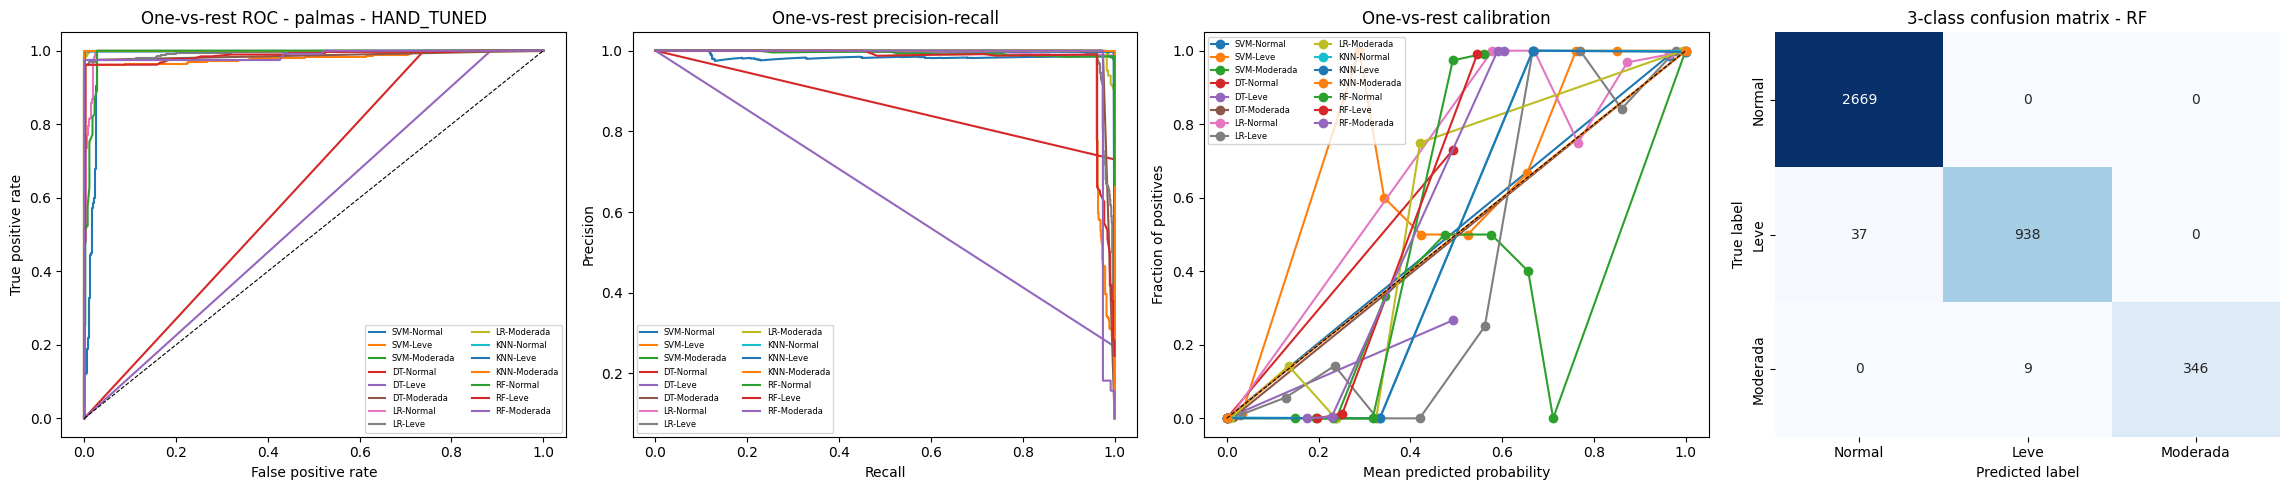

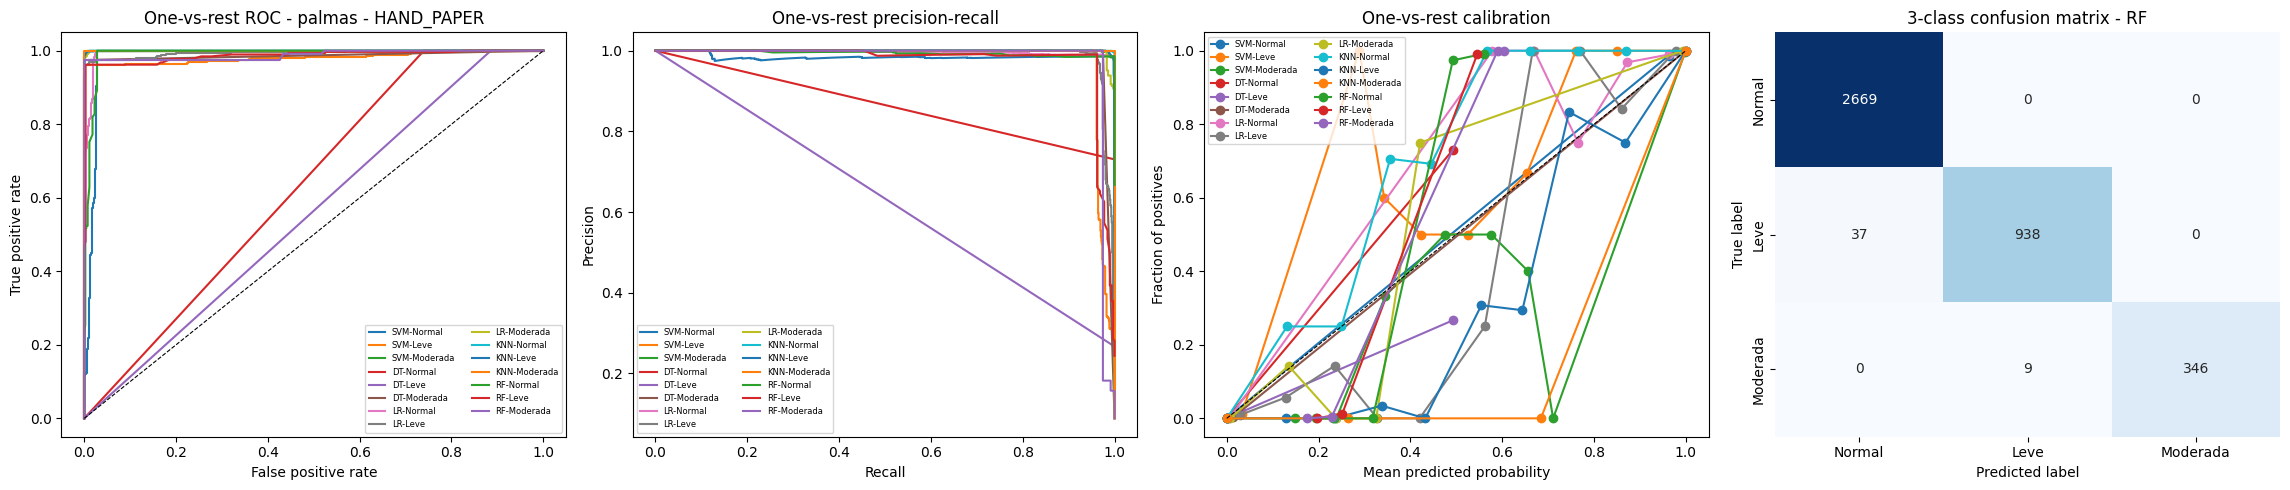

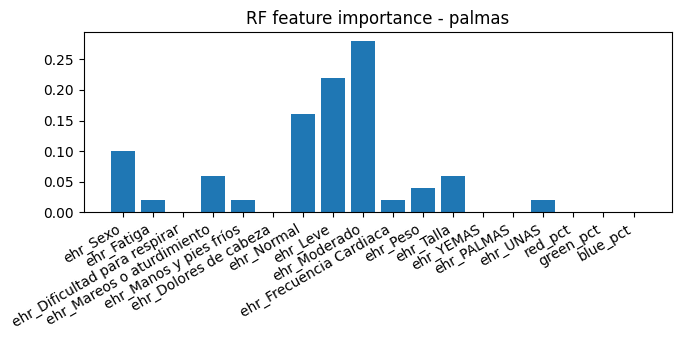

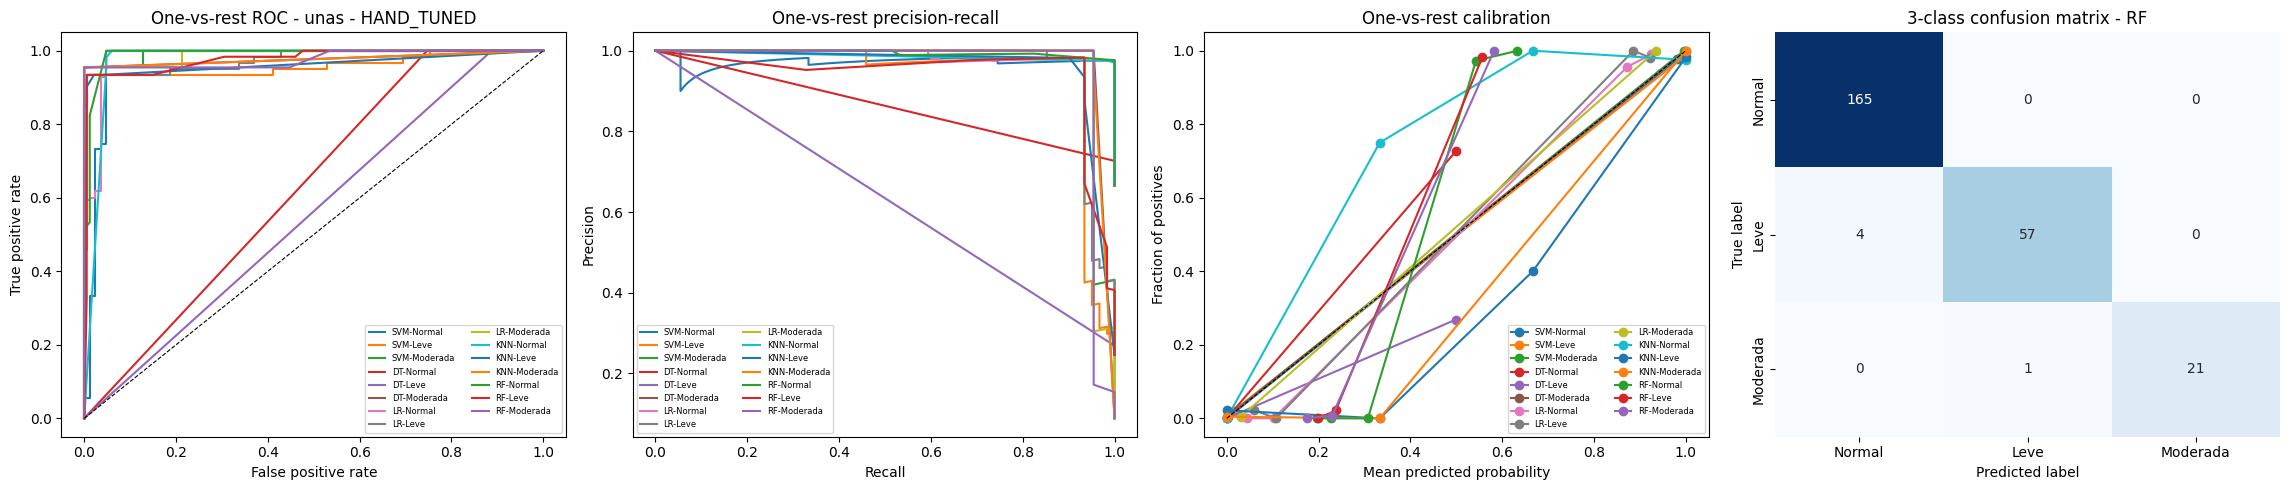

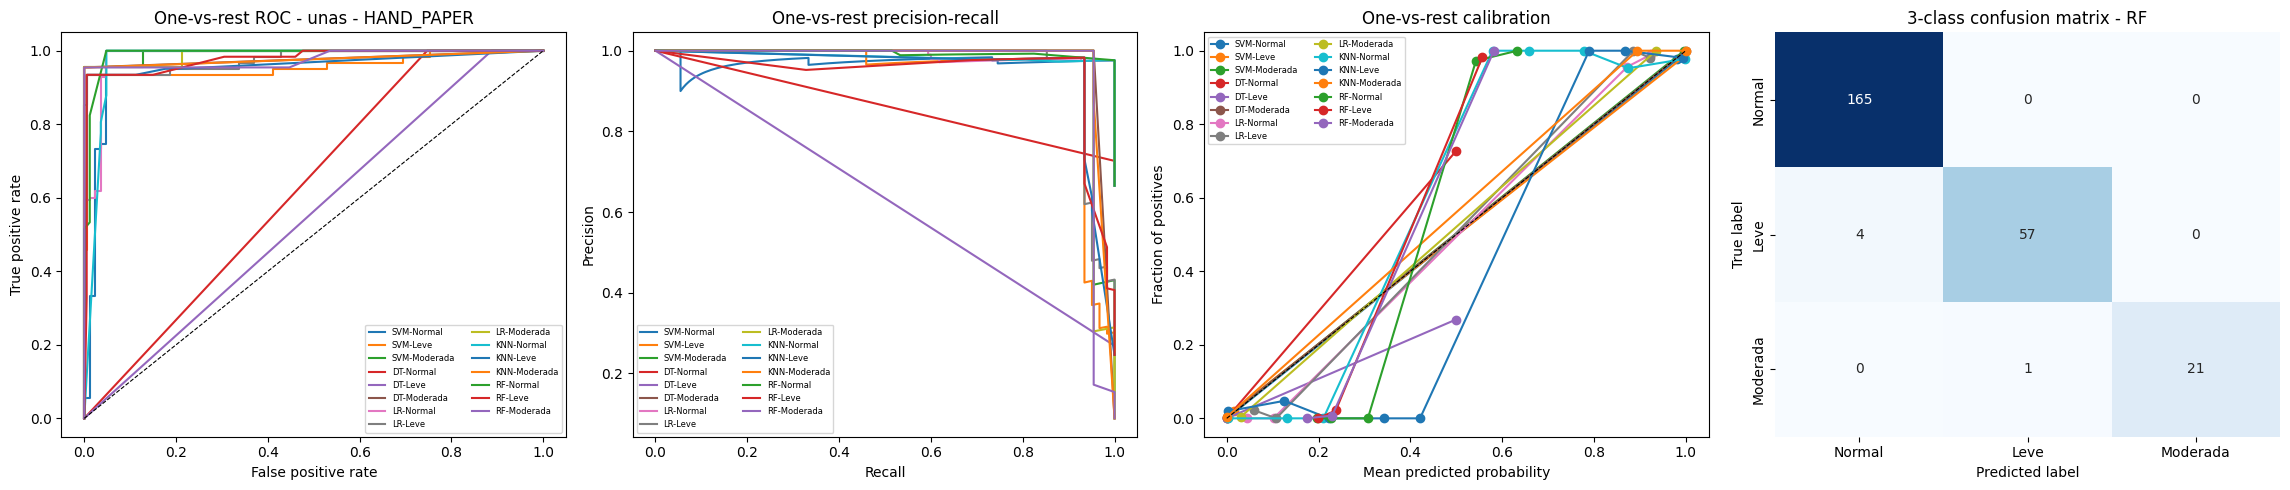

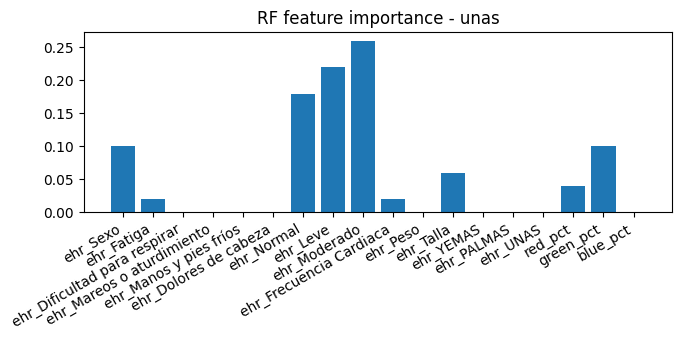

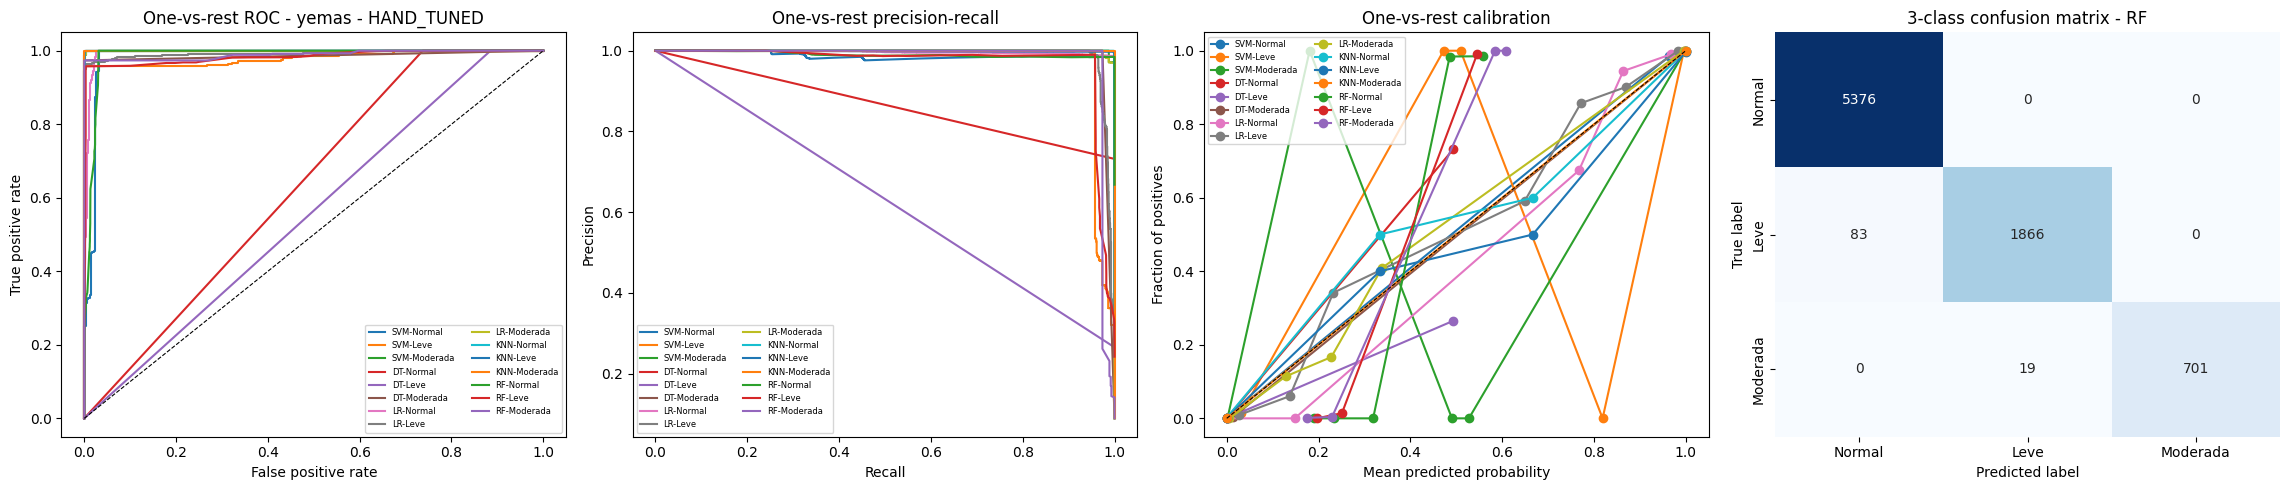

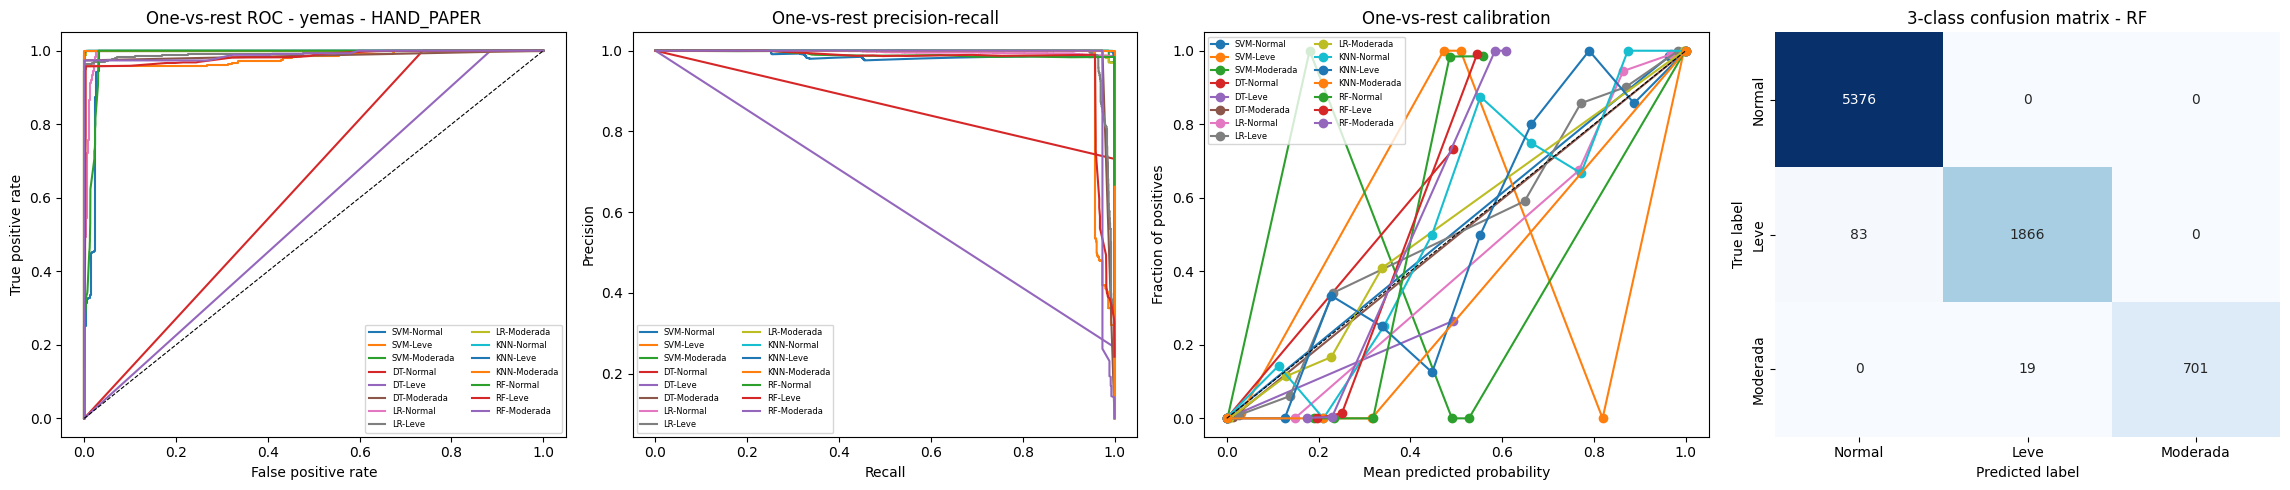

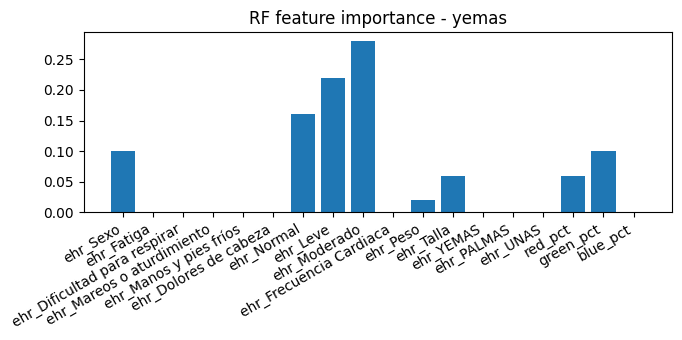

Saved 3-class outputs to /kaggle/working/anemia_ramzan_3class_ckpt


In [26]:
# CELL 10 - multiclass summary tables and plots (Normal / Leve / Moderada)
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
import seaborn as sns

rows = []
for f in sorted((WORK / "results").glob("*__*__*.json")):
    r = json.load(open(f)); t = r["test"]
    rows.append(dict(site=r["site"], exp=r["exp"], model=r["model"],
                     accuracy=t["accuracy"], auc_macro_ovr=t["auc"],
                     precision_macro=t["precision"], recall_macro=t["recall"],
                     f1_macro=t["f1"], mcc=t["mcc"],
                     confusion_matrix=json.dumps(t["confusion_matrix"])))
res = pd.DataFrame(rows)
res.to_csv(WORK / "summary_all_metrics.csv", index=False)
titles = {"TEXT": "Table 2 (textual / EHR dataset)", "IMG": "Table 2 (image dataset)",
          "FUSION_SKB": "Table 3 (feature fusion, SelectKBest)",
          "HAND_TUNED": "Section 4.3 (handcrafted multimodal, GridSearchCV)",
          "HAND_PAPER": "Table 4 (ablation, paper's parameters)"}
for exp, title in titles.items():
    t = res[res.exp == exp]
    if t.empty: continue
    print(f"\\n===== {title} — 3-class macro metrics")
    for site in SITES:
        sub = t[t.site == site].set_index("model")[["accuracy", "auc_macro_ovr", "precision_macro", "recall_macro", "f1_macro", "mcc"]]
        if len(sub):
            print(f"--- {site}")
            display((sub * 100).round(2))

# One-vs-rest ROC / PR / calibration for each class; full 3x3 confusion matrix.
for site in SITES:
    for exp in ["HAND_TUNED", "HAND_PAPER"]:
        names = [m for m in ["SVM", "DT", "LR", "KNN", "RF"]
                 if (WORK / "results" / f"{site}__{exp}__{m}.json").exists()]
        if not names: continue
        fig, ax = plt.subplots(1, 4, figsize=(23, 5))
        for m in names:
            z = np.load(WORK / "results" / f"{site}__{exp}__{m}_probs.npz")
            y = z["y"].astype(int)
            probs = z["prob"]
            for cls_id, cls_name in enumerate(CLASS_NAMES):
                y_bin = (y == cls_id).astype(int)
                if len(np.unique(y_bin)) > 1:
                    fpr, tpr, _ = roc_curve(y_bin, probs[:, cls_id])
                    ax[0].plot(fpr, tpr, label=f"{m}-{cls_name}")
                    pr, rc, _ = precision_recall_curve(y_bin, probs[:, cls_id])
                    ax[1].plot(rc, pr, label=f"{m}-{cls_name}")
                    frac, mean_pred = calibration_curve(y_bin, probs[:, cls_id], n_bins=10, strategy="uniform")
                    ax[2].plot(mean_pred, frac, marker="o", label=f"{m}-{cls_name}")
        ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
        ax[0].set_title(f"One-vs-rest ROC - {site} - {exp}")
        ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
        ax[1].set_title("One-vs-rest precision-recall")
        ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
        ax[2].plot([0, 1], [0, 1], "k--", lw=.8)
        ax[2].set_title("One-vs-rest calibration")
        ax[2].set_xlabel("Mean predicted probability"); ax[2].set_ylabel("Fraction of positives")
        for a in ax[:3]: a.legend(fontsize=6, ncol=2)
        best = "RF" if "RF" in names else names[0]
        cm = np.array(json.load(open(WORK / "results" / f"{site}__{exp}__{best}.json"))["test"]["confusion_matrix"])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[3],
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax[3].set_title(f"3-class confusion matrix - {best}")
        ax[3].set_xlabel("Predicted label"); ax[3].set_ylabel("True label")
        plt.tight_layout()
        plt.savefig(WORK / "plots" / f"{site}__{exp}.png", dpi=140)
        plt.show()
    f = WORK / "models" / f"{site}__HAND_TUNED__RF.joblib"
    if f.exists():
        rf = joblib.load(f)
        fn = json.load(open(WORK / "results" / f"{site}__HAND_TUNED__RF.json"))["features"]
        imp = rf.named_steps["clf"].feature_importances_
        plt.figure(figsize=(7, 3.5)); plt.bar(fn, imp)
        plt.xticks(rotation=30, ha="right"); plt.title(f"RF feature importance - {site}")
        plt.tight_layout(); plt.savefig(WORK / "plots" / f"{site}__feature_importance.png", dpi=140); plt.show()
print("Saved 3-class outputs to", WORK)


In [32]:
import shutil
import os

folder = "/kaggle/working/anemia_ramzan_3class_ckpt"
output = "/kaggle/working/anemia_ramzan_3class_ckpt.zip"

if os.path.isdir(folder):
    shutil.make_archive(
        "/kaggle/working/anemia_ramzan_3class_ckpt",
        "zip",
        root_dir="/kaggle/working",
        base_dir="anemia_ramzan_3class_ckpt"
    )
    print("ZIP created:", output)
    print("Size (MB):", round(os.path.getsize(output) / (1024**2), 2))
else:
    print("Folder not found:", folder)

ZIP created: /kaggle/working/anemia_ramzan_3class_ckpt.zip
Size (MB): 1837.27
